In [16]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from tensorflow.keras.utils import to_categorical

IMAGE_DIR = Path("../data/glagolitic")     
IMG_SIZE = 128                     
GROUP_SPLIT = True                
SEED = 42

files = sorted(IMAGE_DIR.glob("*.png"))
parts = [f.stem.split("_") for f in files]
letters = [p[0] for p in parts]                                  
sessions = np.array(["_".join(p[1:3]) for p in parts])         
CLASSES = sorted(set(letters))

print(len(files), "images,", len(CLASSES), "classes:", CLASSES)
print(len(set(sessions)), "distinct date/time stamps")
assert len(CLASSES) == 11, "expected 11 letters - check the prefixes printed above"

def load_image(path):
    im = Image.open(path).convert("RGBA")
    paper = Image.new("RGBA", im.size, (255, 255, 255, 255))
    im = Image.alpha_composite(paper, im).convert("L")          
    
    if im.size != (IMG_SIZE, IMG_SIZE):
        im = im.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    
    return 1.0 - np.asarray(im, dtype=np.float32) / 255.0        

X = np.stack([load_image(f) for f in files])[..., None]          
y = np.array([CLASSES.index(l) for l in letters])

1286 images, 11 classes: ['crbvb', 'erb', 'glagoli', 'ju', 'myslite', 'rbci', 'sa', 'slovo', 'sta', 'tvrbdo', 'vede']
178 distinct date/time stamps


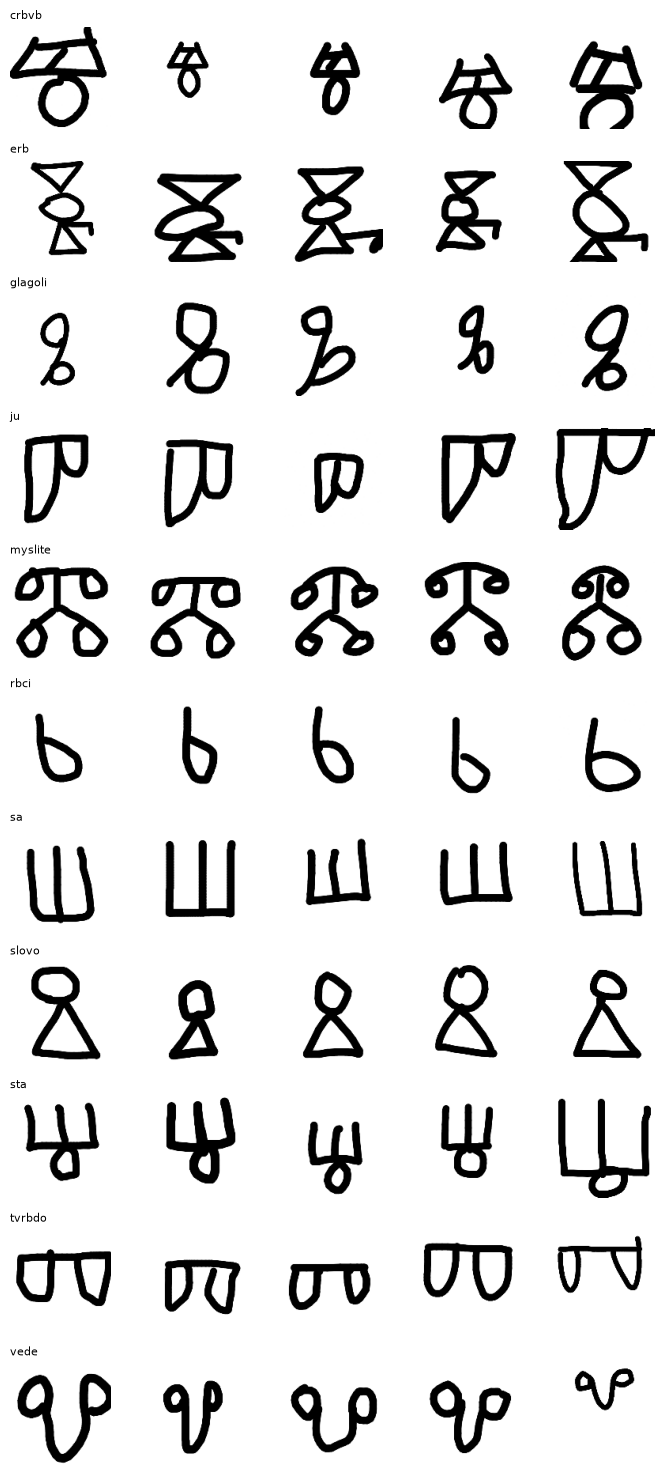

In [17]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(7, 1.35 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    for a, i in zip(axes[r], np.random.default_rng(0).choice(np.where(y == r)[0], 5, replace=False)):
        a.imshow(X[i, ..., 0], cmap="gray_r"); a.axis("off")
    axes[r][0].set_title(c, fontsize=8, loc="left")
plt.tight_layout(); plt.show()

In [18]:
if GROUP_SPLIT:      # 7 folds: 1 for test, 1 for validation, 5 for training (about 14% / 14% / 72%)
    folds = [te for _, te in StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y, sessions)]
    test_idx, val_idx, train_idx = folds[0], folds[1], np.concatenate(folds[2:])
else:
    train_idx, rest = train_test_split(np.arange(len(y)), test_size=0.30, stratify=y, random_state=SEED)
    val_idx, test_idx = train_test_split(rest, test_size=0.50, stratify=y[rest], random_state=SEED)

shared = set(sessions[train_idx]) & (set(sessions[val_idx]) | set(sessions[test_idx]))
print("time stamps shared between train and validation/test:", len(shared))
count = lambda idx: np.bincount(y[idx], minlength=len(CLASSES))
print(pd.DataFrame({"letter": CLASSES, "train": count(train_idx), "validation": count(val_idx), "test": count(test_idx)}).to_string(index=False))

X_train, y_train, X_val, y_val, X_test, y_test = X[train_idx], y[train_idx], X[val_idx], y[val_idx], X[test_idx], y[test_idx]
np.savez_compressed("glagolitic_prepared.npz", X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test, classes=np.array(CLASSES))


time stamps shared between train and validation/test: 0
 letter  train  validation  test
  crbvb     55          13    13
    erb    103          23    18
glagoli     67          16    15
     ju    107          18    17
myslite     63          13    12
   rbci     87          16    21
     sa     97          17    23
  slovo     70          12    12
    sta     70          17    16
 tvrbdo     95          17    17
   vede    110          18    18


In [19]:
from tensorflow import keras
from tensorflow.keras import layers

MAX_EPOCHS, PATIENCE, BATCH = 40, 6, 32
RESULTS, MODELS = Path("results_cnn"), Path("models_cnn")
RESULTS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)

d = np.load("glagolitic_prepared.npz")
X_train, y_train, X_val, y_val, X_test, y_test = (d[k] for k in ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"])
CLASSES = list(d["classes"]); N_CLASSES = len(CLASSES)
Y_train, Y_val, Y_test = (to_categorical(a, N_CLASSES) for a in (y_train, y_val, y_test))

def build_cnn(filters, dense=64, dropout=0.0, gap=False):
    """filters: one convolution (3x3) + max-pooling per entry; gap=True uses global average pooling instead of Flatten."""
    stack = [keras.Input(X_train.shape[1:])]
    for f in filters:
        stack += [layers.Conv2D(f, 3, padding="same", activation="relu"), layers.MaxPooling2D()]
    stack.append(layers.GlobalAveragePooling2D() if gap else layers.Flatten())
    if dense:
        stack.append(layers.Dense(dense, activation="relu"))
    if dropout:
        stack.append(layers.Dropout(dropout))
    stack.append(layers.Dense(N_CLASSES, activation="softmax"))
    model = keras.Sequential(stack)
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

In [ ]:
def report(r):
    print(f"{r['name']:26s} params={r['params']:>9,}  epochs={r['epochs_run']:2d}  {r['seconds']:5.0f}s  "
          f"val_acc={r['val_acc']:.3f}  test_acc={r['test_acc']:.3f}")

def run_experiment(name, filters, dense=64, gap=False, dropout=0.0, force=False):
    path = RESULTS / f"{name}.json"
    if path.exists() and not force:                              # finished runs are loaded, not repeated
        result = json.loads(path.read_text())
        report(result)
        return result
    
    keras.utils.set_random_seed(SEED)
    
    model = build_cnn(filters, dense, dropout, gap)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t = time.perf_counter()
    
    h = model.fit(X_train, Y_train, validation_data=(X_val, Y_val), epochs=MAX_EPOCHS,
                  batch_size=BATCH, callbacks=[stop], verbose=0)
    
    seconds = time.perf_counter() - t
    test_loss, test_acc = model.evaluate(X_test, Y_test, batch_size=64, verbose=0)
    pred = model.predict(X_test, batch_size=64, verbose=0).argmax(1)
    recall = [float((pred[y_test == c] == c).mean()) if (y_test == c).any() else float("nan") for c in range(N_CLASSES)]
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    
    best = int(np.argmin(hist["val_loss"]))
    result = dict(name=name, filters=filters, dense=dense, gap=gap, dropout=dropout, params=int(model.count_params()),
                  epochs_run=len(hist["loss"]), best_epoch=best + 1, seconds=round(seconds, 1),
                  val_acc=hist["val_accuracy"][best], val_loss=hist["val_loss"][best],
                  test_acc=float(test_acc), test_loss=float(test_loss), recall=recall, history=hist)
    model.save(MODELS / f"{name}.keras")
    
    path.write_text(json.dumps(result))
    report(result)
    return result

In [21]:
ARCH = {                                   # name: (conv filters, dense units, global average pooling?)
    "c16-32_fc64":       ([16, 32],       64,  False),
    "c32-64_fc128":      ([32, 64],       128, False),
    "c16-32-64_fc128":   ([16, 32, 64],   128, False),
    "c32-64-128_fc128":  ([32, 64, 128],  128, False),
    "c32-64_gap":        ([32, 64],       0,   True),
    "c32-64-128_gap":    ([32, 64, 128],  0,   True),
}
EXPERIMENTS  = [(f"{a}_d0.0", *ARCH[a], 0.0) for a in ARCH]                                       # sizes, no dropout
EXPERIMENTS += [(f"{a}_d{p}", *ARCH[a], p) for a in ("c32-64_fc128", "c32-64-128_gap") for p in (0.3, 0.5)]  # dropout
print(len(EXPERIMENTS), "experiments")

for exp in EXPERIMENTS:          # slow part: safe to stop and restart, finished runs are skipped
    run_experiment(*exp)

10 experiments
c16-32_fc64_d0.0           params=2,102,731  epochs= 7     16s  val_acc=0.700  test_acc=0.769
c32-64_fc128_d0.0          params=8,408,971  epochs= 7     38s  val_acc=0.722  test_acc=0.791
c16-32-64_fc128_d0.0       params=2,121,995  epochs=10     25s  val_acc=0.861  test_acc=0.857
c32-64-128_fc128_d0.0      params=4,288,523  epochs= 7     51s  val_acc=0.761  test_acc=0.824
c32-64_gap_d0.0            params=   19,531  epochs=40    171s  val_acc=0.533  test_acc=0.571
c32-64-128_gap_d0.0        params=   94,091  epochs=30    262s  val_acc=0.733  test_acc=0.835
c32-64_fc128_d0.3          params=8,408,971  epochs=14    114s  val_acc=0.822  test_acc=0.879
c32-64_fc128_d0.5          params=8,408,971  epochs=11     89s  val_acc=0.783  test_acc=0.819
c32-64-128_gap_d0.3        params=   94,091  epochs=40    351s  val_acc=0.756  test_acc=0.852
c32-64-128_gap_d0.5        params=   94,091  epochs=40    387s  val_acc=0.739  test_acc=0.868
